In [4]:
import os

print(os.listdir('/content'))

['.config', 'sample_data']


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

file_path = '/content/AmesHousing.csv'

if os.path.exists(file_path):
    df = pd.read_csv(file_path)

    print("Dataset loaded successfully!")
    print("\nFirst 5 rows:")
    print(df.head())

    print("\nDataset shape:", df.shape)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nTop 15 columns with missing values:")
    print(df.isnull().sum().sort_values(ascending=False).head(15))

else:
    print("AmesHousing.csv not found. Please upload the dataset.")

    from google.colab import files
    uploaded = files.upload()

    filename = next(
        (name for name in uploaded if name.endswith('.csv')),
        None
    )

    if filename:
        df = pd.read_csv(filename)

        print("\nDataset loaded successfully!")
        print("\nFirst 5 rows:")
        print(df.head())

        print("\nDataset shape:", df.shape)

        print("\nColumn names:")
        print(df.columns.tolist())

        print("\nTop 15 columns with missing values:")
        print(df.isnull().sum().sort_values(ascending=False).head(15))
    else:
        print("Please upload the AmesHousing.csv file.")



AmesHousing.csv not found. Please upload the dataset.


Saving AmesHousing.csv to AmesHousing.csv

Dataset loaded successfully!

First 5 rows:
   Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street  \
0      1  526301100           20        RL         141.0     31770   Pave   
1      2  526350040           20        RH          80.0     11622   Pave   
2      3  526351010           20        RL          81.0     14267   Pave   
3      4  526353030           20        RL          93.0     11160   Pave   
4      5  527105010           60        RL          74.0     13830   Pave   

  Alley Lot Shape Land Contour  ... Pool Area Pool QC  Fence Misc Feature  \
0   NaN       IR1          Lvl  ...         0     NaN    NaN          NaN   
1   NaN       Reg          Lvl  ...         0     NaN  MnPrv          NaN   
2   NaN       IR1          Lvl  ...         0     NaN    NaN         Gar2   
3   NaN       Reg          Lvl  ...         0     NaN    NaN          NaN   
4   NaN       IR1          Lvl  ...         0     NaN  MnPrv     

In [6]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

df = df.drop(columns=['Order', 'PID'])

X = df.drop(columns=['SalePrice'])
y = df['SalePrice']

num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object']).columns

print("Numerical features:", len(num_cols))
print("Categorical features:", len(cat_cols))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data:", X_train_processed.shape)
print("Testing data:", X_test_processed.shape)


Numerical features: 36
Categorical features: 43
Training data: (2344, 300)
Testing data: (586, 300)


In [7]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

model = LinearRegression()

model.fit(X_train_processed, y_train)

y_pred = model.predict(X_test_processed)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression Results")
print("-------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Percentage:", round(r2 * 100, 2), "%")


Linear Regression Results
-------------------------
MAE: 17553.0
RMSE: 30216.15
R2 Score: 0.8861
R2 Percentage: 88.61 %


In [8]:

results = pd.DataFrame({
    'Actual Price': y_test.iloc[:5].values,
    'Predicted Price': model.predict(X_test_processed[:5])
})

results['Predicted Price'] = results['Predicted Price'].round(2)

print(results)


   Actual Price  Predicted Price
0        161000        146044.65
1        116000        109349.49
2        196500        186299.19
3        123600        127674.01
4        126000        140788.45


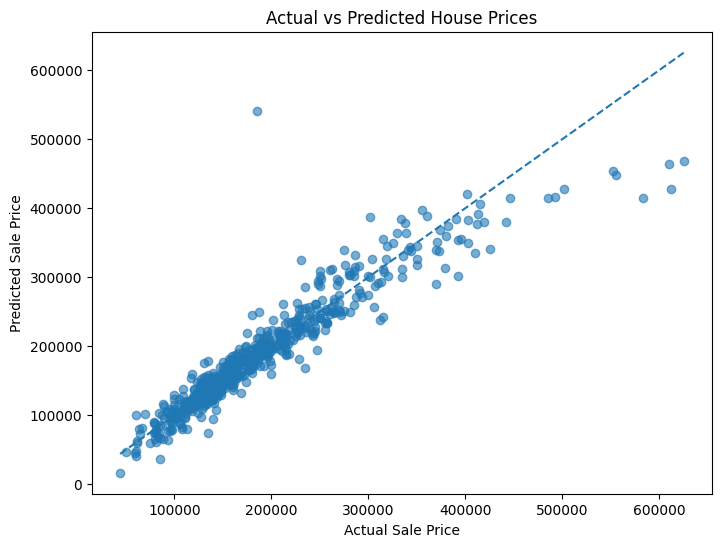

In [9]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")
plt.show()


In [10]:

import joblib

joblib.dump(model, 'house_price_model.pkl')

joblib.dump(preprocessor, 'house_price_preprocessor.pkl')

print("Model and preprocessing pipeline saved successfully!")


Model and preprocessing pipeline saved successfully!


In [11]:

from google.colab import files

files.download('house_price_model.pkl')
files.download('house_price_preprocessor.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

sample_house = X.iloc[[0]]

predicted_price = model.predict(
    preprocessor.transform(sample_house)
)[0]

print("House features:")
print(sample_house[['Overall Qual', 'Gr Liv Area',
                    'Garage Cars', 'Year Built']])

print("\nPredicted Sale Price: $", round(predicted_price, 2))
print("Actual Sale Price: $", y.iloc[0])


House features:
   Overall Qual  Gr Liv Area  Garage Cars  Year Built
0             6         1656          2.0        1960

Predicted Sale Price: $ 220765.72
Actual Sale Price: $ 215000


In [13]:

new_house = X_test.iloc[[0]]

new_prediction = model.predict(
    preprocessor.transform(new_house)
)[0]

actual_price = y_test.iloc[0]

print("Predicted Sale Price: $", round(new_prediction, 2))
print("Actual Sale Price: $", round(actual_price, 2))
print("Absolute Error: $", round(abs(new_prediction - actual_price), 2))


Predicted Sale Price: $ 146044.65
Actual Sale Price: $ 161000
Absolute Error: $ 14955.35


In [14]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R² Score:", round(rf_r2, 4))
print("R² Percentage:", round(rf_r2 * 100, 2), "%")


Random Forest Results
MAE: 15731.1
RMSE: 26335.19
R² Score: 0.9135
R² Percentage: 91.35 %


In [15]:

import joblib

joblib.dump(rf_model, 'random_forest_house_price_model.pkl')

print("Random Forest model saved successfully!")


Random Forest model saved successfully!


In [16]:

from google.colab import files

files.download('house_price_model.pkl')
files.download('house_price_preprocessor.pkl')
files.download('random_forest_house_price_model.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:

import joblib

loaded_model = joblib.load('random_forest_house_price_model.pkl')
loaded_preprocessor = joblib.load('house_price_preprocessor.pkl')

sample_house = X_test.iloc[[0]]

sample_processed = loaded_preprocessor.transform(sample_house)
predicted_price = loaded_model.predict(sample_processed)[0]

print("Predicted House Price: $", round(predicted_price, 2))
print("Actual House Price: $", round(y_test.iloc[0], 2))


Predicted House Price: $ 186116.16
Actual House Price: $ 161000


In [18]:
import os

print(os.listdir('/content'))

['.config', 'house_price_preprocessor.pkl', 'random_forest_house_price_model.pkl', 'house_price_model.pkl', 'AmesHousing.csv', 'sample_data']


In [19]:
from google.colab import files

uploaded = files.upload()

Saving AmesHousing.csv to AmesHousing (1).csv


In [20]:
import pandas as pd

df = pd.read_csv('AmesHousing.csv')

print(df.head())
print("Dataset shape:", df.shape)

   Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street  \
0      1  526301100           20        RL         141.0     31770   Pave   
1      2  526350040           20        RH          80.0     11622   Pave   
2      3  526351010           20        RL          81.0     14267   Pave   
3      4  526353030           20        RL          93.0     11160   Pave   
4      5  527105010           60        RL          74.0     13830   Pave   

  Alley Lot Shape Land Contour  ... Pool Area Pool QC  Fence Misc Feature  \
0   NaN       IR1          Lvl  ...         0     NaN    NaN          NaN   
1   NaN       Reg          Lvl  ...         0     NaN  MnPrv          NaN   
2   NaN       IR1          Lvl  ...         0     NaN    NaN         Gar2   
3   NaN       Reg          Lvl  ...         0     NaN    NaN          NaN   
4   NaN       IR1          Lvl  ...         0     NaN  MnPrv          NaN   

  Misc Val Mo Sold Yr Sold Sale Type  Sale Condition  SalePrice  
0       

In [21]:
print("Dataset shape:", df.shape)
print(df.head())
print("Missing values:", df.isnull().sum().sum())

Dataset shape: (2930, 82)
   Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street  \
0      1  526301100           20        RL         141.0     31770   Pave   
1      2  526350040           20        RH          80.0     11622   Pave   
2      3  526351010           20        RL          81.0     14267   Pave   
3      4  526353030           20        RL          93.0     11160   Pave   
4      5  527105010           60        RL          74.0     13830   Pave   

  Alley Lot Shape Land Contour  ... Pool Area Pool QC  Fence Misc Feature  \
0   NaN       IR1          Lvl  ...         0     NaN    NaN          NaN   
1   NaN       Reg          Lvl  ...         0     NaN  MnPrv          NaN   
2   NaN       IR1          Lvl  ...         0     NaN    NaN         Gar2   
3   NaN       Reg          Lvl  ...         0     NaN    NaN          NaN   
4   NaN       IR1          Lvl  ...         0     NaN  MnPrv          NaN   

  Misc Val Mo Sold Yr Sold Sale Type  Sale Condi

In [22]:
import joblib
import pandas as pd

model = joblib.load('random_forest_house_price_model.pkl')
preprocessor = joblib.load('house_price_preprocessor.pkl')

sample_house = X_test.iloc[[0]]

sample_processed = preprocessor.transform(sample_house)

predicted_price = model.predict(sample_processed)[0]

print("Predicted House Price: $", round(predicted_price, 2))
print("Actual House Price: $", round(y_test.iloc[0], 2))

Predicted House Price: $ 186116.16
Actual House Price: $ 161000


In [23]:
import pandas as pd

print("Number of input features:", len(X.columns))
print(list(X.columns))

Number of input features: 79
['MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Garage Cars', 'Garage Area', 'Garage Qual', 'Garage Cond', 'Paved Drive'

In [24]:
def predict_house_price(new_house):

    new_house = new_house[X.columns]

    processed_house = preprocessor.transform(new_house)

    predicted_price = rf_model.predict(processed_house)[0]

    print(f"Predicted House Price: ${predicted_price:,.2f}")

In [25]:
new_house = X_test.iloc[[0]].copy()

predict_house_price(new_house)

print("Actual House Price:", y_test.iloc[0])

Predicted House Price: $186,116.16
Actual House Price: 161000


In [30]:
import os

print(os.listdir('/content'))

['.config', 'house_price_preprocessor.pkl', 'AmesHousing (2).csv', 'AmesHousing (1).csv', 'random_forest_house_price_model.pkl', 'house_price_model.pkl', 'AmesHousing.csv', 'sample_data']


In [31]:
min_price = df['SalePrice'].min()
max_price = df['SalePrice'].max()
avg_price = df['SalePrice'].mean()

print(f"Minimum House Price: ${min_price:,.0f}")
print(f"Maximum House Price: ${max_price:,.0f}")
print(f"Average House Price: ${avg_price:,.2f}")
print(f"House Price Range: ${min_price:,.0f} to ${max_price:,.0f}")


Minimum House Price: $12,789
Maximum House Price: $755,000
Average House Price: $180,796.06
House Price Range: $12,789 to $755,000


In [32]:

assert 'SalePrice' in df.columns, "SalePrice column not found!"

min_price = df['SalePrice'].min()
max_price = df['SalePrice'].max()

print("Minimum House Price: $", format(min_price, ",.0f"))
print("Maximum House Price: $", format(max_price, ",.0f"))
print("Price range test: PASSED")


Minimum House Price: $ 12,789
Maximum House Price: $ 755,000
Price range test: PASSED


In [33]:
avg_price = df['SalePrice'].mean()

print(f"Average House Price: ${avg_price:,.2f}")

Average House Price: $180,796.06


In [34]:

sample_house = X_test.iloc[[0]].copy()

predicted_price = rf_model.predict(
    preprocessor.transform(sample_house)
)[0]

print("House features:")
print(sample_house.T)

print(f"\nPredicted House Price: ${predicted_price:,.2f}")
print(f"Actual House Price: ${y_test.iloc[0]:,.2f}")


House features:
                  1357
MS SubClass         70
MS Zoning           RM
Lot Frontage       NaN
Lot Area          5100
Street            Pave
...                ...
Misc Val             0
Mo Sold              6
Yr Sold           2008
Sale Type          WD 
Sale Condition  Normal

[79 rows x 1 columns]

Predicted House Price: $186,116.16
Actual House Price: $161,000.00


In [35]:

new_house = X_test.iloc[[0]].copy()

new_house.loc[:, 'Overall Qual'] = 8
new_house.loc[:, 'Gr Liv Area'] = 2000
new_house.loc[:, 'Garage Cars'] = 2
new_house.loc[:, 'Year Built'] = 2010

processed_house = preprocessor.transform(new_house)
predicted_price = rf_model.predict(processed_house)[0]

print("Features used:", new_house.shape[1])
print(f"Predicted House Price: ${predicted_price:,.2f}")


Features used: 79
Predicted House Price: $200,848.96


In [36]:
%%writefile README.md

Writing README.md
